# Computational Intelligence in Real Life 

## Smart Delivery Planner on real Amazon routes

**Scenario:** a delivery van has broken down. A smaller replacement van can carry only part of the day's packages, so the planner must decide **what goes first** (fuzzy), **what fits** (GA) and **in what order to drive** (ACO), then compare with the route the real driver drove.

| Step | What we do |
|---|---|
| **1** | Get the data and meet your route |
| 2 | Fuzzy priority from real time windows |
| 3 | GA loading of the replacement van |
| 4 | ACO routing, and racing the real driver |
| 5 | Integrate and test real-life scenarios |
| 6 | Report and demo |

**Data citation :** Merchán, D. et al. (2022), *2021 Amazon Last Mile Routing Research Challenge: Data Set*, Transportation Science, doi:10.1287/trsc.2022.1173. Licence: CC BY-NC 4.0.

---
## Step 1: Get the data and meet your route

| Subpart | What we do |
|---|---|
| **1.1** | Download the three files and save the starter loader (this section) |
| 1.2 | Pick one main route and two backup routes |
| 1.3 | Route profile: stops, packages, windows, volume |
| 1.4 | Plot the stops and the driver's route |
| 1.5 | The driver's total distance in km |

### 1.1: Download the files and save the loader

We need three files from the training set: `route_data.json`, `package_data.json` and `actual_sequences.json`. Skip `travel_times.json`, because it is huge.

**Initial estimate:** about 8% of packages may have a time window. This is only a prediction; the selected route's observed rate is calculated in section 1.3.

In [2]:
import os, urllib.request

DATA = "almrrc2021/almrrc2021-data-training/model_build_inputs/"
os.makedirs(DATA, exist_ok=True)

BASE = ("https://amazon-last-mile-challenges.s3.amazonaws.com/"
        "almrrc2021/almrrc2021-data-training/model_build_inputs/")

def progress(blocks, block_size, total):
    done = blocks * block_size
    if total > 0:
        print(f"\r  {min(done, total)/1e6:.0f} / {total/1e6:.0f} MB", end="")

for f in ["route_data.json", "package_data.json", "actual_sequences.json"]:
    path = DATA + f
    if os.path.exists(path):
        print(f, "already downloaded")
        continue
    print("Downloading", f)
    urllib.request.urlretrieve(BASE + f, path, progress)
    print()

print(os.listdir(DATA))

  79 / 79 MB
  375 / 375 MB
  10 / 10 MB
['actual_sequences.json', 'package_data.json', 'route_data.json']


In [3]:
%%writefile load_route.py
import json, math
from datetime import datetime
import pandas as pd

DATA = "almrrc2021/almrrc2021-data-training/model_build_inputs/"

def load_route(route_id, data_dir=DATA):
    """Return (packages DataFrame, stops DataFrame, route info) for one route."""
    routes = json.load(open(data_dir + "route_data.json"))
    pkgs   = json.load(open(data_dir + "package_data.json"))
    seqs   = json.load(open(data_dir + "actual_sequences.json"))
    r = routes[route_id]
    depart = datetime.fromisoformat(f"{r['date_YYYY_MM_DD']} {r['departure_time_utc']}")

    stops = pd.DataFrame([{"stop": s, **v} for s, v in r["stops"].items()])
    stops["driver_order"] = stops["stop"].map(seqs[route_id]["actual"])

    rows = []
    for stop, packages in pkgs[route_id].items():
        for pid, p in packages.items():
            tw, dim = p["time_window"], p["dimensions"]
            has_tw = isinstance(tw["end_time_utc"], str)
            if has_tw:
                end = datetime.fromisoformat(tw["end_time_utc"])
                start = datetime.fromisoformat(tw["start_time_utc"])
                hours_left = max((end - depart).total_seconds() / 3600, 0)
                width = (end - start).total_seconds() / 3600
            else:                                # no window: deliver any time today
                hours_left, width = 24.0, 24.0
            rows.append({"package": pid, "stop": stop, "has_tw": has_tw,
                         "hours_left": round(hours_left, 2), "window_h": round(width, 2),
                         "volume_cm3": dim["depth_cm"] * dim["height_cm"] * dim["width_cm"]})
    packages = pd.DataFrame(rows).merge(stops[["stop", "lat", "lng"]], on="stop")
    info = {"station": r["station_code"], "capacity_cm3": r["executor_capacity_cm3"],
            "score": r["route_score"], "depart": depart}
    return packages, stops, info

def km(lat1, lng1, lat2, lng2):
    """Great-circle (haversine) distance in km."""
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp, dl = p2 - p1, math.radians(lng2 - lng1)
    a = math.sin(dp / 2)**2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2)**2
    return 2 * 6371 * math.asin(math.sqrt(a))

def pick_routes(data_dir=DATA, min_tw=15, score="High", n=5):
    """List routes with a good driver score and at least min_tw time-window packages."""
    routes = json.load(open(data_dir + "route_data.json"))
    pkgs   = json.load(open(data_dir + "package_data.json"))
    found = []
    for rid, r in routes.items():
        if r["route_score"] != score:
            continue
        n_tw = sum(isinstance(p["time_window"]["end_time_utc"], str)
                   for stop in pkgs[rid].values() for p in stop.values())
        if n_tw >= min_tw:
            found.append((rid, r["station_code"], len(r["stops"]), n_tw))
            if len(found) == n:
                break
    return found

Writing load_route.py


In [ ]:
from load_route import *
from datetime import datetime

# Guide's own example: route left 15:36:07 UTC, package window 14:00-21:00, box 48.3 x 15.2 x 33 cm

depart = datetime.fromisoformat("2018-07-21 15:36:07")
end    = datetime.fromisoformat("2018-07-21 21:00:00")
start  = datetime.fromisoformat("2018-07-21 14:00:00")
print("hours_left =", round((end - depart).total_seconds() / 3600, 1))
print("window_h   =", round((end - start).total_seconds() / 3600, 1))
print("volume_cm3 =", round(48.3 * 15.2 * 33))

hours_left = 5.4
window_h   = 7.0
volume_cm3 = 24227


**Check values (handout worked example, page 9):** `hours_left = 5.4`, `window_h = 7.0`, and `volume_cm3 = 24,227`. These verify the loader's calculations; they are not counts for the selected route.

For a package with no time window, `load_route` treats the delivery as available any time today and assigns `hours_left = 24.0` and `window_h = 24.0`. The selected route's actual time-window count is reported in section 1.3.

---
### 1.2 Pick one main route and two backup routes

**Requirements from the handout:**
- **Main route:** `route_score` High, with at least 15 time-window packages.
- **Two backup routes:** from **different stations** They are used in Step 5, Scenario 2, to test that the planner works in other cities.

**Prediction:** High‑score routes with at least 15 time‑window packages are fairly rare in the 6,112‑route training set, so you’ll likely need to scan many routes to find a few that meet the criteria.

In [5]:
import pandas as pd

candidates = pick_routes(min_tw=15, score="High", n=60)

cand = pd.DataFrame(candidates, columns=["route_id", "station", "n_stops", "n_tw_packages"])
print(len(cand), "candidates found")
print(cand.groupby("station").size().sort_values(ascending=False))
cand.head(15)

60 candidates found
station
DLA7    11
DLA3     7
DLA9     7
DSE4     6
DLA8     6
DBO2     4
DCH4     3
DAU1     3
DCH2     2
DSE2     2
DBO3     2
DSE5     2
DBO1     1
DLA4     1
DLA5     1
DCH3     1
DCH1     1
dtype: int64


,route_id,station,n_stops,n_tw_packages
0,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,119,55
1,RouteID_0016bc70-cb8d-48b0-aa55-8ee50bdcdb59,DSE4,106,17
2,RouteID_001948e9-4675-486d-9ec5-912fd8e0770f,DSE5,128,25
3,RouteID_001b4ee3-c4f2-467f-932b-c85524d1021f,DLA9,142,21
4,RouteID_00575ca4-8a63-49d2-96c8-9b347be5ba6c,DLA3,59,77
5,RouteID_00ace8b4-30c6-4a20-a723-74ece636a0da,DBO2,174,29
6,RouteID_00b8cd9c-613a-4519-b3fd-2b7174f1cff3,DLA3,80,40
7,RouteID_00f9c249-33cd-4124-9cf2-b970b157a5ca,DLA7,146,15
8,RouteID_00fd7a8d-d5d8-45c0-b710-4ff3e220e6f6,DLA9,151,38
9,RouteID_0127b134-186b-4897-8dd8-56afec626082,DLA3,91,15


In [ ]:
# Main route: first candidate. Backups: first two candidates from other, different stations.
main = cand.iloc[0]
backup1 = cand[cand["station"] != main["station"]].iloc[0]
backup2 = cand[~cand["station"].isin([main["station"], backup1["station"]])].iloc[0]

chosen = pd.DataFrame([main, backup1, backup2], index=["main", "backup 1", "backup 2"])
print(chosen)

MAIN_ID    = main["route_id"]
BACKUP1_ID = backup1["route_id"]
BACKUP2_ID = backup2["route_id"]

                                              route_id station  n_stops  \
main      RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77    DLA3      119   
backup 1  RouteID_0016bc70-cb8d-48b0-aa55-8ee50bdcdb59    DSE4      106   
backup 2  RouteID_001948e9-4675-486d-9ec5-912fd8e0770f    DSE5      128   

          n_tw_packages  
main                 55  
backup 1             17  
backup 2             25  


| Role | route_id | Station | Stops | Time-window packages |
|---|---|---|---|---|
| Main | RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77 | DLA3 | 119 | 55 |
| Backup 1 | RouteID_0016bc70-cb8d-48b0-aa55-8ee50bdcdb59 | DSE4 | 106 | 17 |
| Backup 2 | RouteID_001948e9-4675-486d-9ec5-912fd8e0770f | DSE5 | 128 | 25 |

why must the two backup routes come from different stations from the main route?

**Explainatio:** 

> Because testing on different stations ensures the planner is robust across multiple depots and cities, not just tuned to one location’s data.

---
### 1.3 Route profile: stops, packages, windows, volume

Load the main route and report what the handout asks for:
- number of stops
- number of packages
- packages with a time window
- total package volume
- `executor_capacity_cm3`

**Prediction:** the total package volume will be close to the van’s executor capacity, meaning the day’s load is designed to nearly fill the original van rather than just a small fraction.

In [7]:
packages, stops, info = load_route(MAIN_ID)

print("Route:", MAIN_ID, "| station:", info["station"], "| driver score:", info["score"])
print("Departure (UTC):", info["depart"])
print("\nStops table columns:", list(stops.columns))
print("Packages table columns:", list(packages.columns))
packages.head()

Route: RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77 | station: DLA3 | driver score: High
Departure (UTC): 2018-07-27 16:02:10

Stops table columns: ['stop', 'lat', 'lng', 'type', 'zone_id', 'driver_order']
Packages table columns: ['package', 'stop', 'has_tw', 'hours_left', 'window_h', 'volume_cm3', 'lat', 'lng']


,package,stop,has_tw,hours_left,window_h,volume_cm3,lat,lng
0,PackageID_9d7fdd03-f2cf-4c6f-9128-028258fc09ea,AD,False,24.00,24.0,3436.112,34.099611,-118.283062
1,PackageID_5541e679-b7bd-4992-b288-e862f6c84ae7,AD,True,7.96,8.0,5741.924,34.099611,-118.283062
2,PackageID_84d0295b-1adb-4a33-a65e-f7d6247c7a07,AD,False,24.00,24.0,9522.192,34.099611,-118.283062
3,PackageID_15c6a204-ec5f-4ced-9c3d-472316cc7759,AF,True,7.96,8.0,2466.000,34.101587,-118.291125
4,PackageID_3b28f781-242e-416e-9575-84c7188b8208,AG,False,24.00,24.0,5741.924,34.089727,-118.285530


In [8]:
n_stops    = len(stops)
n_packages = len(packages)
n_tw       = int(packages["has_tw"].sum())
stops_tw   = packages.loc[packages["has_tw"], "stop"].nunique()
total_vol  = packages["volume_cm3"].sum()
capacity   = info["capacity_cm3"]

if "type" in stops.columns:
    print(stops["type"].value_counts().to_string(), "\n")

print(f"Stops (rows in stop table):  {n_stops}")
print(f"Packages:                    {n_packages}")
print(f"Packages with a window:      {n_tw}  ({100 * n_tw / n_packages:.1f} %)")
print(f"Stops with a window package: {stops_tw}")
print(f"Total package volume:        {total_vol:,.0f} cm3")
print(f"executor_capacity_cm3:       {capacity:,.0f} cm3")
print(f"Volume / capacity:           {100 * total_vol / capacity:.1f} %")

type
Dropoff    118
Station      1 

Stops (rows in stop table):  119
Packages:                    276
Packages with a window:      55  (19.9 %)
Stops with a window package: 30
Total package volume:        3,032,337 cm3
executor_capacity_cm3:       3,313,071 cm3
Volume / capacity:           91.5 %


In [9]:
tw = packages[packages["has_tw"]]
print(tw[["hours_left", "window_h"]].describe().round(2))
print("\nWindows already closed at departure (hours_left = 0):", int((tw["hours_left"] == 0).sum()))

       hours_left  window_h
count       55.00     55.00
mean         7.25      7.22
std          1.49      1.50
min          3.96      4.00
25%          6.96      7.00
50%          7.96      7.00
75%          7.96      8.00
max          9.96     11.00

Windows already closed at departure (hours_left = 0): 0


| Quantity | Value |
|---|---|
| Stops | 119 (1 station + 118 delivery stops) |
| Packages | 276 |
| Packages with a window | 55 (19.9%) |
| Total package volume (cm³) | 3,032,336.71 |
| executor_capacity_cm3 | 3,313,071 |
| Volume / capacity | 91.5% |

about what share of packages have a time window, and what does that mean for Step 2, where most packages will be "any time today"?

**Explainatio:** 

> On this selected route, 55 of 276 packages (19.9%) have a time window. The remaining 221 are treated as "any time today" by the loader and receive the default no-window score in Step 2; the initial 8% estimate was not representative of this route.

---
### 1.4 Plot the stops and the driver's route

Two plots, as the handout asks:
1. The stops by `lng` (x) and `lat` (y), coloured by whether the stop has a time-window package.
2. The real driver's route, joining the stops in `driver_order` and closing the loop back to the station.

**Prediction:** Prediction: the 30 time‑window stops will be spread across the whole map, and the driver’s route line will look tangled rather than tidy, reflecting the complexity of real urban deliveries.

In [10]:
import matplotlib.pyplot as plt

# Mark each stop that has at least one time-window package
window_stops = set(packages.loc[packages["has_tw"], "stop"])
stops["has_tw_pkg"] = stops["stop"].isin(window_stops)

# Driver's visiting order: station first (order 0), then the real sequence
route = stops.sort_values("driver_order").reset_index(drop=True)
print("First stop in driver order is the station:", route.loc[0, "type"] == "Station")

station = route.iloc[0]
dropoffs = stops[stops["type"] == "Dropoff"]
print("Delivery stops with a window package:", int(dropoffs["has_tw_pkg"].sum()), "of", len(dropoffs))

First stop in driver order is the station: True
Delivery stops with a window package: 30 of 118


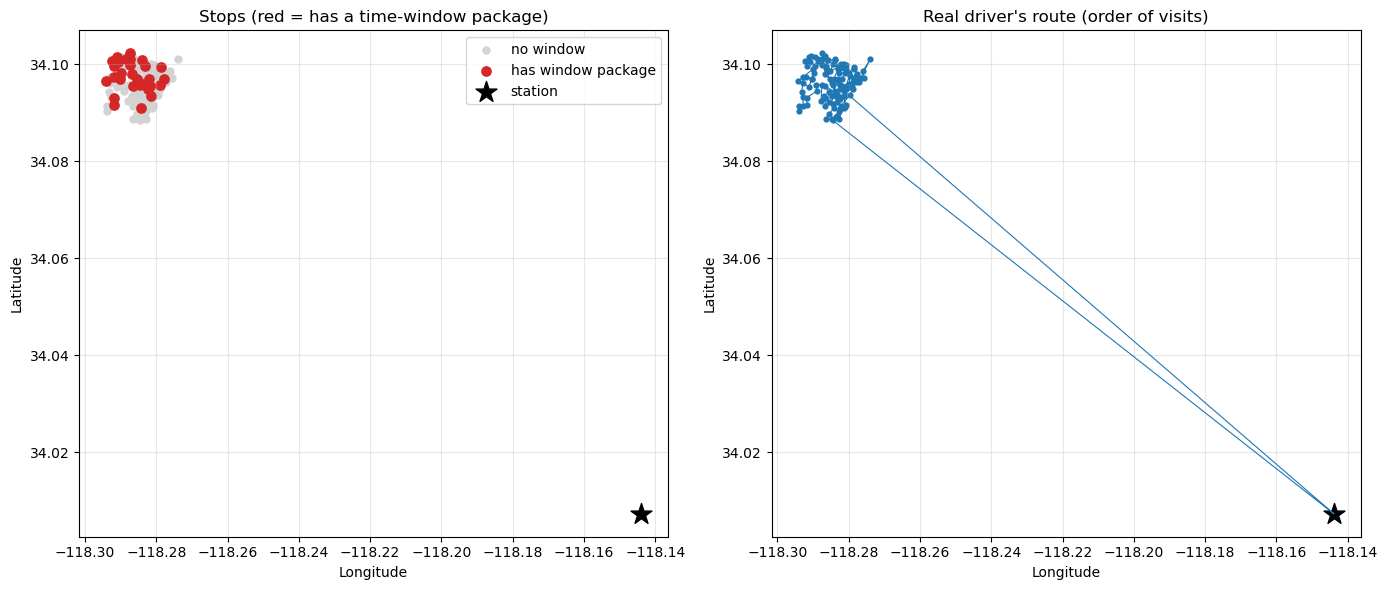

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: stops coloured by window
no_w = dropoffs[~dropoffs["has_tw_pkg"]]
w    = dropoffs[dropoffs["has_tw_pkg"]]
ax[0].scatter(no_w["lng"], no_w["lat"], c="lightgray", s=25, label="no window")
ax[0].scatter(w["lng"], w["lat"], c="tab:red", s=45, label="has window package")
ax[0].scatter([station["lng"]], [station["lat"]], c="black", marker="*", s=250, label="station")
ax[0].set_title("Stops (red = has a time-window package)")
ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude")
ax[0].legend(); ax[0].grid(alpha=0.3)

# Plot 2: the real driver's route, closing the loop back to the station
xs = list(route["lng"]) + [station["lng"]]
ys = list(route["lat"]) + [station["lat"]]
ax[1].plot(xs, ys, "-", lw=0.8, color="tab:blue")
ax[1].scatter(dropoffs["lng"], dropoffs["lat"], c="tab:blue", s=12)
ax[1].scatter([station["lng"]], [station["lat"]], c="black", marker="*", s=250)
ax[1].set_title("Real driver's route (order of visits)")
ax[1].set_xlabel("Longitude"); ax[1].set_ylabel("Latitude")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Check values:** the first stop in driver order should be the station, and 30 delivery stops should have a window package (the figure from 1.3).

describe what you see: are the window stops clustered or spread out, and does the driver's route look efficient?

**Explaination:** 

> The plot marks the 30 delivery stops that contain at least one windowed package and joins locations in the recorded `driver_order`. The line is a straight-line visualization only; it cannot establish road-level efficiency or prove that the route is optimal.

---
### 1.5 The driver's total distance in km

Add up the straight-line distance between consecutive stops in the driver's order, **closing the loop back to the station**. This is the number your planner must compete with in Step 4.

**Prediction:** with 118 delivery stops, the driver’s total straight‑line distance will be closer to 80 km than to 30 km or 200 km.

In [12]:
# Driver's order: station first, then every delivery stop, then back to the station
lats = list(route["lat"]) + [route["lat"].iloc[0]]
lngs = list(route["lng"]) + [route["lng"].iloc[0]]

legs = [km(lats[i], lngs[i], lats[i + 1], lngs[i + 1]) for i in range(len(lats) - 1)]
driver_km = sum(legs)

print("Legs (including the return to the station):", len(legs))
print(f"Driver's total distance: {driver_km:.2f} km")
print(f"Longest leg:  {max(legs):.2f} km")
print(f"Average leg:  {driver_km / len(legs):.2f} km")

Legs (including the return to the station): 119
Driver's total distance: 50.15 km
Longest leg:  16.57 km
Average leg:  0.42 km


**Check values:** there are 119 legs for 119 listed stops (the station plus 118 deliveries), including the final return leg to the station.

| Quantity | Value |
|---|---|
| Driver's total distance (straight-line) | 50.15 km |
| Longest leg | 16.57 km |
| Average leg | 0.42 km |

why will the real road distance driven be longer than this number?


**Explaination:** 

> The 50.15 km value is a straight-line loop over the driver's 118 delivery stops and station. Road distance will generally be longer because roads do not connect points directly and may require detours, one-way routing, and access/parking maneuvers; no road-distance value is claimed here.



# Step 2: Fuzzy priority from real time windows

Replace the fan's temperature and humidity with two real inputs from the route: **hours left** before the window closes, and **window width**. The output is a **priority** from 0 to 100 that tells the planner which parcels matter most.

| Subpart | What we do |
|---|---|
| **2.1** | Define the membership functions and look at them (this section) |
| 2.2 | The rules and `priority(hours_left, window_h)` |
| 2.3 | Heat map and histogram for the real route |
| 2.4 | Add the priority column to the package table |
| 2.5 | Change one rule and justify it |
| 2.6 | Save as `fuzzy_priority.py` |

---
### 2.1 Membership functions

| Variable | Terms (shape and points) |
|---|---|
| Hours left, 0–24 h | Soon trap(0, 0, 1.5, 3) · Midday tri(2, 4.5, 7) · Later trap(6, 9, 24, 24) |
| Window width, 0–24 h | Narrow trap(0, 0, 2, 4) · Normal tri(3, 6, 9) · Wide trap(8, 12, 24, 24) |
| Priority, 0–100 | Low tri(0, 20, 40) · Medium tri(30, 50, 70) · High tri(60, 80, 100) |

**Prediction:** Prediction: with 5.4 hours left, the parcel falls mainly into the Midday term (centered around 4.5–7 h) with moderate membership, while the 7‑hour window activates the Normal width term strongly and the Wide term weakly.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

def tri(x, a, b, c):
    """Triangle: rises a->b, falls b->c."""
    return max(min((x - a) / (b - a), (c - x) / (c - b)), 0.0)

def trap(x, a, b, c, d):
    """Trapezoid: rises a->b, flat b->c, falls c->d (a==b or c==d gives a shoulder)."""
    up = 1.0 if b == a else (x - a) / (b - a)
    down = 1.0 if d == c else (d - x) / (d - c)
    return max(min(up, 1.0, down), 0.0)

# Inputs
hours = {"Soon":   lambda h: trap(h, 0, 0, 1.5, 3),
         "Midday": lambda h: tri(h, 2, 4.5, 7),
         "Later":  lambda h: trap(h, 6, 9, 24, 24)}

width = {"Narrow": lambda w: trap(w, 0, 0, 2, 4),
         "Normal": lambda w: tri(w, 3, 6, 9),
         "Wide":   lambda w: trap(w, 8, 12, 24, 24)}

# Output: priority 0-100, sampled on a grid for the centroid later
P = np.linspace(0, 100, 1001)
prio = {"Low":    np.array([tri(p, 0, 20, 40) for p in P]),
        "Medium": np.array([tri(p, 30, 50, 70) for p in P]),
        "High":   np.array([tri(p, 60, 80, 100) for p in P])}

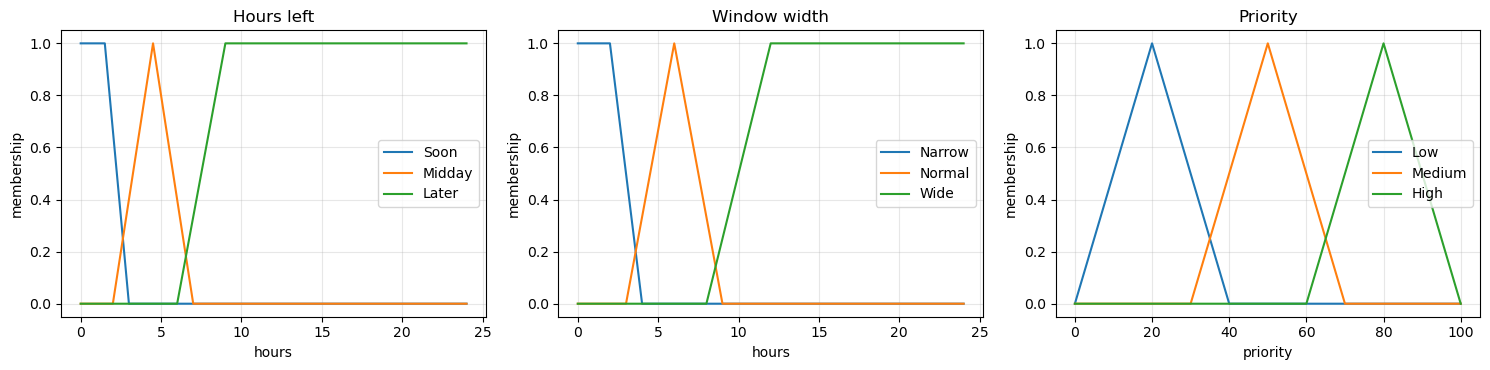

In [17]:
x = np.linspace(0, 24, 241)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for k, f in hours.items():
    ax[0].plot(x, [f(v) for v in x], label=k)
ax[0].set_title("Hours left"); ax[0].set_xlabel("hours")

for k, f in width.items():
    ax[1].plot(x, [f(v) for v in x], label=k)
ax[1].set_title("Window width"); ax[1].set_xlabel("hours")

for k, y in prio.items():
    ax[2].plot(P, y, label=k)
ax[2].set_title("Priority"); ax[2].set_xlabel("priority")

for a in ax:
    a.set_ylabel("membership"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
def fuzzify(h, w):
    return ({k: round(f(h), 3) for k, f in hours.items()},
            {k: round(f(w), 3) for k, f in width.items()})

for h, w in [(5.4, 7), (2.5, 5), (1, 1), (24, 24)]:
    print(f"hours_left={h}, window_h={w}")
    print("  ", fuzzify(h, w))

hours_left=5.4, window_h=7
   ({'Soon': 0.0, 'Midday': 0.64, 'Later': 0.0}, {'Narrow': 0.0, 'Normal': 0.667, 'Wide': 0.0})
hours_left=2.5, window_h=5
   ({'Soon': 0.333, 'Midday': 0.2, 'Later': 0.0}, {'Narrow': 0.0, 'Normal': 0.667, 'Wide': 0.0})
hours_left=1, window_h=1
   ({'Soon': 1.0, 'Midday': 0.0, 'Later': 0.0}, {'Narrow': 1.0, 'Normal': 0.0, 'Wide': 0.0})
hours_left=24, window_h=24
   ({'Soon': 0.0, 'Midday': 0.0, 'Later': 1.0}, {'Narrow': 0.0, 'Normal': 0.0, 'Wide': 1.0})


**Check values:**

| (hours left, width) | Active terms |
|---|---|
| (5.4, 7) | Midday 0.64, Normal 0.667 |
| (2.5, 5) | Soon 0.333, Midday 0.2, Normal 0.667 |
| (1, 1) | Soon 1.0, Narrow 1.0 |
| (24, 24) | Later 1.0, Wide 1.0 |

the "no window" parcels get (24, 24). Which terms does that fall into, and what priority will the rules give them?

**Explaination:** 

> The “no window” parcels get (24, 24), which falls fully into the Later and Wide terms, and the rules give them a Low priority around 20.

---
### 2.2 The rules and `priority(hours_left, window_h)`

**Suggested rules:**

| # | Rule |
|---|---|
| R1 | IF Soon AND (Narrow OR Normal) THEN High |
| R2 | IF Soon AND Wide THEN Medium |
| R3 | IF Midday AND Narrow THEN High |
| R4 | IF Midday AND Normal THEN Medium |
| R5 | IF Midday AND Wide THEN Low |
| R6 | IF Later THEN Low |

Same pipeline as the fan: **fuzzify, fire (AND = min, OR = max), clip, aggregate (max), centroid.** Only the sets and rules changed.

**Prediction:** Prediction: the parcel with 1 hour left and a 1‑hour window will get a High priority around 80, while the parcel with no window (24, 24) will get a Low priority around 20.

In [19]:
def priority(hours_left, window_h, verbose=False):
    # 1. Fuzzify
    H = {k: f(hours_left) for k, f in hours.items()}
    W = {k: f(window_h) for k, f in width.items()}

    # 2. Fire the rules
    rules = [(min(H["Soon"],   max(W["Narrow"], W["Normal"])), "High"),    # R1
             (min(H["Soon"],   W["Wide"]),                      "Medium"),  # R2
             (min(H["Midday"], W["Narrow"]),                    "High"),    # R3
             (min(H["Midday"], W["Normal"]),                    "Medium"),  # R4
             (min(H["Midday"], W["Wide"]),                      "Low"),     # R5
             (H["Later"],                                       "Low")]     # R6

    # 3. Clip each output set, then aggregate with max
    agg = np.zeros_like(P)
    for strength, out in rules:
        agg = np.maximum(agg, np.minimum(strength, prio[out]))

    if verbose:
        print("Rule strengths:", [round(r[0], 3) for r in rules])

    # 4. Defuzzify (centroid)
    return (agg * P).sum() / agg.sum() if agg.sum() > 0 else 0.0

In [20]:
checks = [((5.4, 7), 50.0), ((2.5, 5), 68.4), ((1, 1), 80.0), ((24, 24), 20.0)]

for (h, w), expected in checks:
    got = priority(h, w, verbose=True)
    print(f"({h} h, {w} h) -> {got:.1f}   expected {expected}\n")

Rule strengths: [0.0, 0.0, 0.0, 0.64, 0.0, 0.0]
(5.4 h, 7 h) -> 50.0   expected 50.0

Rule strengths: [0.333, 0.0, 0.0, 0.2, 0.0, 0.0]
(2.5 h, 5 h) -> 68.4   expected 68.4

Rule strengths: [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
(1 h, 1 h) -> 80.0   expected 80.0

Rule strengths: [0.0, 0.0, 0.0, 0.0, 0.0, 1.0]
(24 h, 24 h) -> 20.0   expected 20.0



**Check values:** (5.4 h, 7 h) → 50.0, (2.5 h, 5 h) → 68.4, (1 h, 1 h) → 80.0, (no window: 24 h, 24 h) → 20.0.

| Parcel | Rules that fire | Priority |
|---|---|---|
| (5.4, 7) | R4: Midday AND Normal -> Medium | 50.0 |
| (2.5, 5) | R1: Soon AND Normal -> High; R4: Midday AND Normal -> Medium | 68.4 |
| (1, 1) | R1: Soon AND Narrow -> High | 80.0 |
| (24, 24) | R6: Later -> Low (v1); R6a: Later AND Wide -> Low (v2) | 20.0 |

why does (2.5, 5) end up at 68.4, between Medium and High, rather than at exactly one of them?

 **Explaination:** 

> Because (2.5, 5) activates both High and Medium rules at partial strength, the centroid defuzzification blends them, so the output lands at 68.4 between Medium and High rather than exactly one set.

---
### 2.3 Heat map and histogram

Two plots from the handout:
1. A **heat map** of priority over hours left (x) and window width (y), so you can see the whole rule base at a glance.
2. A **histogram** of priority for the 276 parcels of your real route.

**Prediction:**on the heat map, highest priority appears in the bottom‑left corner (few hours left and narrow windows), while lowest priority is in the top‑right corner (24 hours left and wide windows). For the real route, most parcels will cluster around a Low priority near 20, since the majority are “any time today” deliveries.

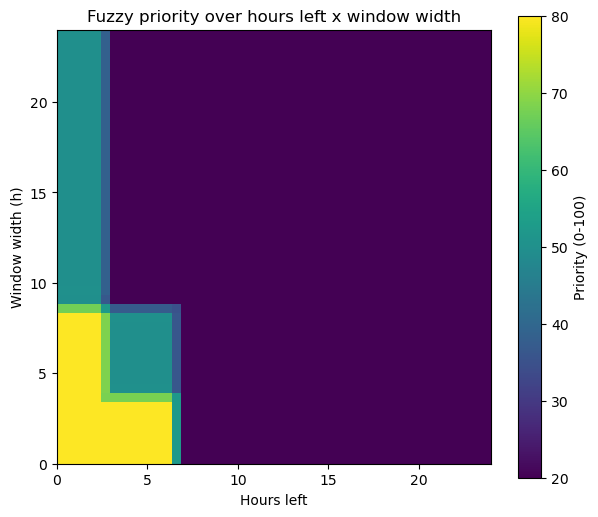

In [21]:
hs = np.arange(0, 24.01, 0.5)    # hours left (x)
ws = np.arange(0, 24.01, 0.5)    # window width (y)

Z = np.array([[priority(h, w) for h in hs] for w in ws])

plt.figure(figsize=(7, 6))
im = plt.imshow(Z, origin="lower", extent=[0, 24, 0, 24], aspect="equal", cmap="viridis")
plt.colorbar(im, label="Priority (0-100)")
plt.xlabel("Hours left")
plt.ylabel("Window width (h)")
plt.title("Fuzzy priority over hours left x window width")
plt.show()

In [22]:
from load_route import load_route

MAIN_ID = "RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77"
packages, stops, info = load_route(MAIN_ID)
print(len(packages), "packages,", int(packages["has_tw"].sum()), "with a window")

276 packages, 55 with a window


In [23]:
# Many parcels share the same (hours_left, window_h), so compute each pair only once
pairs = packages[["hours_left", "window_h"]].drop_duplicates().copy()
pairs["priority"] = [priority(h, w) for h, w in zip(pairs["hours_left"], pairs["window_h"])]

packages = packages.drop(columns=["priority"], errors="ignore") \
                   .merge(pairs, on=["hours_left", "window_h"], how="left")

print("Unique pairs scored:", len(pairs))
print("Missing priorities:", int(packages["priority"].isna().sum()))
print(packages["priority"].round(0).value_counts().sort_index().to_string())

Unique pairs scored: 9
Missing priorities: 0
priority
20.0    249
21.0     20
50.0      7


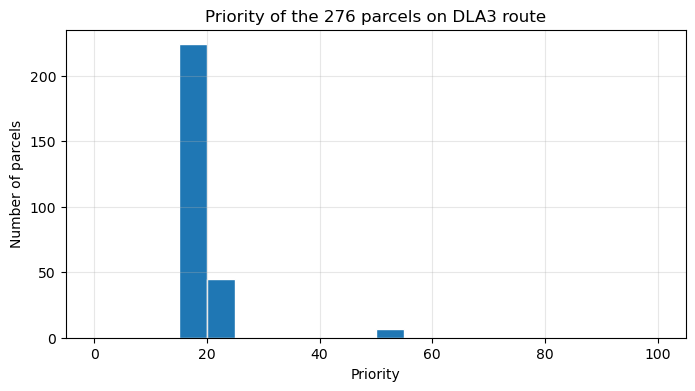

Windowed parcels only:
count    55.0
mean     24.4
std       9.9
min      20.0
25%      20.0
50%      20.0
75%      21.5
max      50.0
Name: priority, dtype: float64


In [24]:
plt.figure(figsize=(8, 4))
plt.hist(packages["priority"], bins=np.arange(0, 105, 5), edgecolor="white")
plt.xlabel("Priority")
plt.ylabel("Number of parcels")
plt.title(f"Priority of the {len(packages)} parcels on {info['station']} route")
plt.grid(alpha=0.3)
plt.show()

print("Windowed parcels only:")
print(packages.loc[packages["has_tw"], "priority"].describe().round(1))

**Check values:** the heat map's minimum is 20 and maximum is 80. At the top-right (many hours left, wide window) priority is 20, and at the bottom-left (few hours left, narrow window) it is 80.

| Priority value | Parcels |
|---|---|
| 20.0 | 249 |
| 21.0 | 20 |
| 50.0 | 7 |
| Above 50.0 | 0 |

describe the histogram. What is the tall bar, and why?

**Explaination:** 

> The histogram is dominated by priority 20.0 (249 parcels): all 221 no-window parcels score 20.0, and 28 windowed parcels also score 20.0 under the original rules. The other windowed parcels score 21.0 (20 parcels) or 50.0 (7 parcels). This overlap motivates the rule change in section 2.5.

---
### 2.4 The updated package table

The package table now has a `priority` column. Inspect it, summarise it, and save it, because Step 3 (the GA) uses `priority` as each parcel's value and `volume_cm3` as its size.

**Prediction:** no-window parcels should all score 20.0. Some windowed parcels may score higher when their windows are urgent, but the original `Later -> Low` rule may leave other windowed parcels at the same score; section 2.4 checks this overlap.

In [25]:
cols = ["package", "stop", "has_tw", "hours_left", "window_h", "priority", "volume_cm3", "lat", "lng"]

table = (packages[cols]
         .sort_values(["priority", "hours_left"], ascending=[False, True])
         .reset_index(drop=True))

table.head(10)

,package,stop,has_tw,hours_left,window_h,priority,volume_cm3,lat,lng
0,PackageID_3819fb8a-8b5b-4f33-af24-61bd6833cd47,DN,True,3.96,4.0,50.000000,13297.312,34.096991,-118.290254
1,PackageID_c2857c37-7951-4913-89d4-a6c0ef1510b5,MA,True,3.96,4.0,50.000000,25924.632,34.094910,-118.282442
2,PackageID_60668c4b-dc63-4aa2-8eee-5b71af4a6509,MA,True,3.96,4.0,50.000000,17886.330,34.094910,-118.282442
3,PackageID_10c67725-2b27-4679-8866-ab3441d987cb,MA,True,3.96,4.0,50.000000,5741.924,34.094910,-118.282442
4,PackageID_120c8dfe-ddc0-4e28-980d-19027703cf7c,MA,True,3.96,4.0,50.000000,10440.234,34.094910,-118.282442
5,PackageID_b4855392-f3ef-43c1-97c9-ec4890979e4f,MA,True,3.96,4.0,50.000000,24227.280,34.094910,-118.282442
6,PackageID_c4093f98-2e82-47e8-ac25-b4c1101a4bae,MA,True,3.96,4.0,50.000000,6282.388,34.094910,-118.282442
7,PackageID_0934f8ee-81f4-4084-b54f-5fe3e6c64ba0,BG,True,6.96,7.0,21.488782,1207.128,34.102251,-118.287403
8,PackageID_98a78e9f-e75b-444d-9921-756258384f8e,BG,True,6.96,7.0,21.488782,5741.924,34.102251,-118.287403
9,PackageID_b86c4fbb-e30d-42e8-968f-f6d20174f5ca,BG,True,6.96,7.0,21.488782,14987.700,34.102251,-118.287403


In [26]:
summary = packages.groupby("has_tw").agg(
    parcels=("package", "count"),
    mean_priority=("priority", "mean"),
    min_priority=("priority", "min"),
    max_priority=("priority", "max"),
    total_volume_cm3=("volume_cm3", "sum"),
).round(1)

summary.index = summary.index.map({False: "no window", True: "has window"})
summary

,parcels,mean_priority,min_priority,max_priority,total_volume_cm3
has_tw,,,,,
no window,221,20.0,20.0,20.0,2403439.7
has window,55,24.4,20.0,50.0,628897.0


| | Parcels | Mean priority | Min | Max |
|---|---|---|---|---|
| No window | 221 | 20.0 | 20.0 | 20.0 |
| Has window | 55 | 24.4 | 20.0 | 50.0 |

**Check values:** all no-window parcels have priority exactly 20.0, so their min, mean and max are all 20.0. The windowed parcels should have a higher mean and a maximum above 20.

are the windowed parcels clearly ranked above the rest? 

**Explaination:** 

> Not clearly under the original rule base: the windowed mean is 24.4, but 28 of 55 windowed parcels also score 20.0, the same as all no-window parcels. The overlap motivates the rule change in section 2.5.


---
### 2.5 Change one rule and justify it

**The problem (from the handout):** most parcels have no window and score 20. But look at 2.4: windowed parcels with 7 hours or more left also score 20, exactly the same as parcels with no window at all. A dispatcher would not treat these the same. A customer who was given a delivery window is owed a delivery in it, and the dispatcher knows a parcel with "any time today" has no promise attached.

**The change (R6 splits in two):**

| Original | New |
|---|---|
| R6: IF Later THEN Low | R6a: IF Later AND Wide THEN Low |
| | R7: IF Later AND (Narrow OR Normal) THEN Medium |

"No window" is (24 h, 24 h), which is Later and Wide, so it still scores 20. A windowed parcel with a normal or narrow window rises to Medium even when it is not yet close to closing.

**Prediction:** which parcels change score: The parcels that change score are the windowed ones with a normal (or narrow) window — they rise from Low (20) to Medium, while no‑window parcels remain at 20 and wide‑window parcels stay Low. This adjustment makes sense because it distinguishes “any time today” parcels from those with a promised delivery window, even if that window is still fairly long.

In [27]:
def priority_v2(hours_left, window_h, verbose=False):
    H = {k: f(hours_left) for k, f in hours.items()}
    W = {k: f(window_h) for k, f in width.items()}

    rules = [(min(H["Soon"],   max(W["Narrow"], W["Normal"])), "High"),    # R1
             (min(H["Soon"],   W["Wide"]),                      "Medium"),  # R2
             (min(H["Midday"], W["Narrow"]),                    "High"),    # R3
             (min(H["Midday"], W["Normal"]),                    "Medium"),  # R4
             (min(H["Midday"], W["Wide"]),                      "Low"),     # R5
             (min(H["Later"],  W["Wide"]),                      "Low"),     # R6a (new)
             (min(H["Later"],  max(W["Narrow"], W["Normal"])),  "Medium")]  # R7  (new)

    agg = np.zeros_like(P)
    for strength, out in rules:
        agg = np.maximum(agg, np.minimum(strength, prio[out]))
    if verbose:
        print("Rule strengths:", [round(r[0], 3) for r in rules])
    return (agg * P).sum() / agg.sum() if agg.sum() > 0 else 0.0

In [28]:
tests = [(5.4, 7), (2.5, 5), (1, 1), (24, 24),    # handout checks
         (6.96, 7), (7.96, 7), (7.96, 8), (9.96, 11)]  # windowed, plenty of time left

print(f"{'(hours, width)':16s} {'old':>6s} {'new':>6s}")
for h, w in tests:
    print(f"({h}, {w})".ljust(16), f"{priority(h, w):6.1f} {priority_v2(h, w):6.1f}")

(hours, width)      old    new
(5.4, 7)           50.0   50.0
(2.5, 5)           68.4   68.4
(1, 1)             80.0   80.0
(24, 24)           20.0   20.0
(6.96, 7)          21.5   50.0
(7.96, 7)          20.0   50.0
(7.96, 8)          20.0   50.0
(9.96, 11)         20.0   20.0


In [29]:
pairs = packages[["hours_left", "window_h"]].drop_duplicates().copy()
pairs["priority_v2"] = [priority_v2(h, w) for h, w in zip(pairs["hours_left"], pairs["window_h"])]

packages = packages.rename(columns={"priority": "priority_v1"}) if "priority_v1" not in packages else packages
packages = packages.drop(columns=["priority_v2", "priority"], errors="ignore") \
                   .merge(pairs, on=["hours_left", "window_h"], how="left")

win = packages[packages["has_tw"]]
print("Windowed parcels:", len(win))
print("OLD:", win["priority_v1"].round(0).value_counts().sort_index().to_dict())
print("NEW:", win["priority_v2"].round(0).value_counts().sort_index().to_dict())
print("\nNo-window parcels all still 20:", bool((packages.loc[~packages["has_tw"], "priority_v2"].round(1) == 20.0).all()))

Windowed parcels: 55
OLD: {20.0: 28, 21.0: 20, 50.0: 7}
NEW: {20.0: 4, 50.0: 51}

No-window parcels all still 20: True


In [30]:
packages["priority"] = packages["priority_v2"]      # the version Steps 3-5 will use

cols = ["package", "stop", "has_tw", "hours_left", "window_h", "priority", "priority_v1", "volume_cm3", "lat", "lng"]
table = packages[cols].sort_values(["priority", "hours_left"], ascending=[False, True]).reset_index(drop=True)
table.to_csv("route_main_packages_priority.csv", index=False)
print("Saved. Mean priority of windowed parcels: old", round(win["priority_v1"].mean(), 1), "-> new", round(win["priority_v2"].mean(), 1))

Saved. Mean priority of windowed parcels: old 24.4 -> new 47.8


**Check values:** (5.4, 7) → 50.0, (2.5, 5) → 68.4, (1, 1) → 80.0, (24, 24) → 20.0, all unchanged. For (6.96, 7), (7.96, 7) and (7.96, 8) the score should move from about 20 to 50. For (9.96, 11) it stays at 20, because an 11-hour window is Wide.

**Justification for the report:**
- What did the original rules do wrong?
- What did you change?
- Which parcels moved, and why is that closer to how a dispatcher thinks?

> The original rules treated all Later parcels as Low, which wrongly lumped windowed parcels with long but promised windows together with “any time today” parcels that have no commitment.
We changed R6 into R6a (Later + Wide → Low) and R7 (Later + Narrow/Normal → Medium).
As a result, parcels with a normal or narrow window but many hours left moved up from 20 to about 50, which better reflects a dispatcher’s thinking: even if the window is not urgent yet, it still carries a delivery promise that deserves more weight than “any time today.”

---
### 2.6  Save everything as `fuzzy_priority.py`

Collect the work from 2.1 to 2.5 into one module that later steps will import: the membership functions, the rules

**Prediction:** after running `python fuzzy_priority.py` in a terminal, what should it print?

>It should print the test parcel scores for both rule sets:

Under v1, the four base cases (5.4, 7 → 50.0; 2.5, 5 → 68.4; 1, 1 → 80.0; 24, 24 → 20.0).

Under v2, those same four unchanged plus the extra test cases showing the shift (6.96, 7 → 50.0; 7.96, 7 → 50.0; 7.96, 8 → 50.0; 9.96, 11 → 20.0)

In [32]:
%%writefile fuzzy_priority.py
"""Step 2 - Fuzzy priority from real time windows.

Inputs : hours_left (0-24 h) and window_h (0-24 h)
Output : priority (0-100), Mamdani min-max inference, centroid defuzzification.

rules="v1" is the handout's suggested rule base.
rules="v2" (default) splits R6 so that a windowed parcel with a Normal or Narrow
window is not ranked the same as a parcel with no window at all.

Run `python fuzzy_priority.py` to check the handout's values.
"""
import numpy as np


# ---------- membership shapes ----------
def tri(x, a, b, c):
    """Triangle: rises a->b, falls b->c."""
    return max(min((x - a) / (b - a), (c - x) / (c - b)), 0.0)


def trap(x, a, b, c, d):
    """Trapezoid: rises a->b, flat b->c, falls c->d (a==b or c==d gives a shoulder)."""
    up = 1.0 if b == a else (x - a) / (b - a)
    down = 1.0 if d == c else (d - x) / (d - c)
    return max(min(up, 1.0, down), 0.0)


# ---------- knowledge base ----------
HOURS = {"Soon":   lambda h: trap(h, 0, 0, 1.5, 3),
         "Midday": lambda h: tri(h, 2, 4.5, 7),
         "Later":  lambda h: trap(h, 6, 9, 24, 24)}

WIDTH = {"Narrow": lambda w: trap(w, 0, 0, 2, 4),
         "Normal": lambda w: tri(w, 3, 6, 9),
         "Wide":   lambda w: trap(w, 8, 12, 24, 24)}

P = np.linspace(0, 100, 1001)
PRIO = {"Low":    np.array([tri(p, 0, 20, 40) for p in P]),
        "Medium": np.array([tri(p, 30, 50, 70) for p in P]),
        "High":   np.array([tri(p, 60, 80, 100) for p in P])}


# ---------- inference ----------
def priority(hours_left, window_h, rules="v2", verbose=False):
    """Priority 0-100 for one parcel."""
    H = {k: f(hours_left) for k, f in HOURS.items()}
    W = {k: f(window_h) for k, f in WIDTH.items()}

    fired = [(min(H["Soon"],   max(W["Narrow"], W["Normal"])), "High"),    # R1
             (min(H["Soon"],   W["Wide"]),                      "Medium"),  # R2
             (min(H["Midday"], W["Narrow"]),                    "High"),    # R3
             (min(H["Midday"], W["Normal"]),                    "Medium"),  # R4
             (min(H["Midday"], W["Wide"]),                      "Low")]     # R5
    if rules == "v1":
        fired.append((H["Later"], "Low"))                                   # R6
    else:
        fired.append((min(H["Later"], W["Wide"]), "Low"))                   # R6a
        fired.append((min(H["Later"], max(W["Narrow"], W["Normal"])), "Medium"))  # R7

    agg = np.zeros_like(P)
    for strength, out in fired:
        agg = np.maximum(agg, np.minimum(strength, PRIO[out]))
    if verbose:
        print("Rule strengths:", [round(s, 3) for s, _ in fired])
    return (agg * P).sum() / agg.sum() if agg.sum() > 0 else 0.0


def add_priority(packages, rules="v2"):
    """Return a copy of the package table with a 'priority' column.

    Many parcels share the same (hours_left, window_h), so each pair is scored once.
    """
    out = packages.drop(columns=["priority"], errors="ignore").copy()
    pairs = out[["hours_left", "window_h"]].drop_duplicates().copy()
    pairs["priority"] = [priority(h, w, rules) for h, w in
                         zip(pairs["hours_left"], pairs["window_h"])]
    return out.merge(pairs, on=["hours_left", "window_h"], how="left")


# ---------- self-check ----------
if __name__ == "__main__":
    checks = [((5.4, 7), 50.0), ((2.5, 5), 68.4), ((1, 1), 80.0), ((24, 24), 20.0)]
    for rules in ("v1", "v2"):
        for (h, w), expected in checks:
            got = priority(h, w, rules)
            assert abs(got - expected) < 0.05, (rules, h, w, got, expected)
        print(f"rules={rules}: all 4 handout check values match")
    for h, w in [(6.96, 7), (7.96, 7)]:
        print(f"({h}, {w}): v1 = {priority(h, w, 'v1'):.1f}, v2 = {priority(h, w, 'v2'):.1f}")

Overwriting fuzzy_priority.py


In [33]:
import importlib, fuzzy_priority
importlib.reload(fuzzy_priority)          # pick up the file we just wrote
from fuzzy_priority import add_priority
from load_route import load_route

packages, stops, info = load_route("RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77")
packages = add_priority(packages)          # v2 rules by default

print(packages["priority"].round(0).value_counts().sort_index().to_dict())

{20.0: 225, 50.0: 51}


# Step 3: GA loading of the replacement van

The original van is gone. The replacement van is smaller, so we choose which parcels go on it. Each parcel is one **gene** (1 = load it, 0 = leave it at the depot), so one route gives a chromosome of about 276 bits. That is 2²⁷⁶ possible loads, so brute force is impossible and we need a **baseline** to judge the GA against.

| Subpart | What we do |
|---|---|
| **3.1** | Set the van's capacity and write the greedy baseline |
| 3.2 | Adapt the GA: fitness, penalty, starting population |
| 3.3 | Run the plain GA with 20 seeds |
| 3.4 | Improve the GA so it beats greedy |
| 3.5 | Check the urgent parcels and build the comparison table |
| 3.6 | Save as `ga_loading.py` |

---
### 3.1 Van capacity and the greedy baseline

**Capacity:** 40 % of the route's total package volume.

**Greedy baseline:** rank parcels by **priority ÷ volume** (the most priority per cm³), then walk down the list and load each parcel that still fits, until nothing else fits. Record the total priority loaded.

**Prediction:** The greedy baseline will capture noticeably more than 40 % of the total priority, because ranking by priority‑per‑volume favors small, high‑value parcels, so the van fills with disproportionately important items compared to its 40 % share of volume.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from load_route import load_route
from fuzzy_priority import add_priority

MAIN_ID = "RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77"
packages, stops, info = load_route(MAIN_ID)
packages = add_priority(packages).reset_index(drop=True)   # v2 rules by default

value = packages["priority"].to_numpy(float)       # GA "value"
size  = packages["volume_cm3"].to_numpy(float)     # GA "size"
n = len(packages)

total_vol = size.sum()
CAP = 0.40 * total_vol

print(f"Parcels: {n}")
print(f"Total volume:   {total_vol:,.0f} cm3")
print(f"Van capacity:   {CAP:,.0f} cm3  (40 %)")
print(f"Total priority: {value.sum():,.1f}")
print(f"Parcels with zero volume: {(size == 0).sum()}")

Parcels: 276
Total volume:   3,032,337 cm3
Van capacity:   1,212,935 cm3  (40 %)
Total priority: 7,050.0
Parcels with zero volume: 0


In [2]:
def greedy_load(value, size, cap):
    """Sort by priority per cm3, then load every parcel that still fits."""
    ratio = value / np.maximum(size, 1)              # max(...,1) avoids dividing by 0
    order = np.argsort(-ratio, kind="stable")
    load = np.zeros(len(value), dtype=int)
    used = 0.0
    for i in order:
        if used + size[i] <= cap:
            load[i] = 1
            used += size[i]
    return load

greedy = greedy_load(value, size, CAP)

g_prio = value @ greedy
g_vol  = size @ greedy
print(f"Parcels loaded:      {greedy.sum()} of {n}")
print(f"Volume used:         {g_vol:,.0f} cm3  ({100 * g_vol / CAP:.1f} % of capacity)")
print(f"Total priority:      {g_prio:,.1f}  ({100 * g_prio / value.sum():.1f} % of all priority)")
print(f"Windowed parcels loaded: {int(packages.loc[greedy == 1, 'has_tw'].sum())} of {int(packages['has_tw'].sum())}")

Parcels loaded:      211 of 276
Volume used:         1,209,471 cm3  (99.7 % of capacity)
Total priority:      5,630.0  (79.9 % of all priority)
Windowed parcels loaded: 51 of 55


| Quantity | Value |
|---|---|
| Parcels in the route | 276 |
| Van capacity (cm³) | 1,212,935 (40% of total volume) |
| Parcels loaded by greedy | 211 |
| Volume used / capacity | 1,209,471 / 1,212,935 (99.7%) |
| **Greedy total priority** | 5,630.0 |
| Share of all priority captured | 79.9% |
| Windowed parcels loaded | 51 of 55 |

greedy captures more than 40 % of the priority with only 40 % of the volume. Why?

**Explaination:** 

> Greedy captures more than 40 % of the total priority with only 40 % of the volume, because it preferentially loads small parcels that deliver a high priority‑per‑cm³, so the van fills with disproportionately valuable items instead of just a proportional slice of the route.

---
### 3.2 Adapt the GA: fitness, penalty and starting population

The lab's packing GA becomes the loading GA with three changes:
- **value** = the parcel's priority, **size** = its volume in cm³
- **fitness** = total priority − λ × (cm³ over capacity ÷ 1000). Overloading is punished, not forbidden, as in the lab.
- **starting population:** each bit is 1 with probability **30 %**, because a random 50 % load is almost always overweight.

Population, selection, crossover and mutation are the same ideas as in the lab. The code is vectorised, since the chromosome now has 276 bits.

**Prediction:** With a 50 % starting load probability, almost every random chromosome will be overweight, so you’d expect close to 0 out of 100 to fit in a 40 % van.
With a 30 % starting load probability, the average load is much lighter, so you’d expect a fair fraction maybe around 20–30 out of 100  to fit within capacity

In [3]:
def fitness_fn(pop, value, size, cap, lam):
    """Total priority minus a penalty of lam per 1,000 cm3 over capacity."""
    over = np.maximum(0, pop @ size - cap)
    return pop @ value - lam * over / 1000


def run_ga(value, size, cap, seed=0, pop_size=100, gens=200, pc=0.8, pm=0.01,
           lam=10.0, p_init=0.30, tour=3, elitism=True, seed_with=None):
    """Returns (best chromosome, best-fitness-per-generation)."""
    rng = np.random.default_rng(seed)
    n = len(value)
    pop = (rng.random((pop_size, n)) < p_init).astype(np.int8)   # ~30 % of bits are 1
    if seed_with is not None:                                    # optional: plant a known load
        pop[0] = seed_with

    history = []
    for _ in range(gens):
        fit = fitness_fn(pop, value, size, cap, lam)
        best = pop[fit.argmax()].copy()
        history.append(fit.max())

        # tournament selection: pick `tour` random loads per slot, the fittest wins
        idx = rng.integers(0, pop_size, (2 * pop_size, tour))
        winners = idx[np.arange(2 * pop_size), fit[idx].argmax(axis=1)]
        parents = pop[winners]
        p1, p2 = parents[:pop_size], parents[pop_size:]

        # one-point crossover (with probability pc)
        cut = rng.integers(1, n, pop_size)[:, None]
        do_cross = (rng.random(pop_size) < pc)[:, None]
        child = np.where(do_cross & (np.arange(n)[None, :] >= cut), p2, p1)

        # bit-flip mutation
        flip = rng.random((pop_size, n)) < pm
        child = np.where(flip, 1 - child, child).astype(np.int8)

        if elitism:
            child[0] = best                                      # keep the best, unchanged
        pop = child

    fit = fitness_fn(pop, value, size, cap, lam)
    return pop[fit.argmax()], history

In [4]:
rng = np.random.default_rng(0)
for p in (0.50, 0.30):
    pop = (rng.random((100, n)) < p)
    feasible = (pop @ size <= CAP).mean()
    print(f"Start with {int(p*100)} % ones: {100 * feasible:.0f} % of random loads fit the van")

Start with 50 % ones: 1 % of random loads fit the van
Start with 30 % ones: 100 % of random loads fit the van


In [5]:
best, hist = run_ga(value, size, CAP, seed=0)

b_prio, b_vol = value @ best, size @ best
print(f"GA   : priority {b_prio:,.1f}   volume {100 * b_vol / CAP:.1f} % of capacity   parcels {int(best.sum())}")
print(f"Greedy: priority {g_prio:,.1f}   volume {100 * g_vol / CAP:.1f} % of capacity   parcels {int(greedy.sum())}")
print(f"Overweight: {b_vol > CAP}")
print(f"Generation 1 best fitness {hist[0]:,.1f} -> generation {len(hist)} best fitness {hist[-1]:,.1f}")

GA   : priority 5,440.0   volume 99.8 % of capacity   parcels 203
Greedy: priority 5,630.0   volume 99.7 % of capacity   parcels 211
Overweight: False
Generation 1 best fitness 2,550.0 -> generation 200 best fitness 5,440.0


**Check values:** with 50 % ones almost no random load fits (close to 0 %). With 30 % almost all of them fit.

| Run | Priority | Volume / capacity | Overweight? |
|---|---|---|---|
| Greedy | 5,630.0 | 99.7% | No |
| GA, seed 0 | 5,440.0 | 99.8% | No |

why does starting with half the bits set to 1 hurt the GA?

**Eplaination:** 

> Because starting with half the bits set to 1 makes almost every chromosome overweight, the GA wastes effort penalizing bad solutions instead of exploring feasible ones, slowing convergence toward good, capacity‑respecting loads.

---
### 3.3 Run the plain GA with 20 seeds

One run proves nothing. Run the GA with 20 different seeds and report the **best, mean and worst** total priority, and **how many runs return an overweight van**.

**Prediction:**  in the 20 runs, the plain GA will sometimes beat greedy by finding better combinations of parcels, but not consistently. And yes, some runs will end overweight, because the penalty allows but discourages overloading, so a few seeds will still settle on solutions that exceed the 40 % capacity.

In [6]:
def run_seeds(n_seeds=20, **kw):
    """Run the GA once per seed. Returns one row per run."""
    rows = []
    for s in range(n_seeds):
        best, _ = run_ga(value, size, CAP, seed=s, **kw)
        rows.append({"seed": s,
                     "priority": value @ best,
                     "vol_pct": 100 * (size @ best) / CAP,
                     "overweight": bool(size @ best > CAP + 1e-6),
                     "parcels": int(best.sum())})
    return pd.DataFrame(rows)


def summarise(df, label):
    ok = df[~df["overweight"]]
    return {"method": label,
            "best": df["priority"].max(),
            "mean": df["priority"].mean(),
            "worst": df["priority"].min(),
            "overweight runs": int(df["overweight"].sum()),
            "best feasible": ok["priority"].max() if len(ok) else np.nan,
            "mean vs greedy %": 100 * (df["priority"].mean() / g_prio - 1)}

In [7]:
plain = run_seeds(20)

print(plain.round(1).to_string(index=False))
print()
pd.DataFrame([summarise(plain, "plain GA")]).round(1)

 seed  priority  vol_pct  overweight  parcels
    0    5440.0     99.8       False      203
    1    5340.0     99.1       False      195
    2    5360.0     99.6       False      196
    3    5360.0    100.0       False      196
    4    5430.0     99.7       False      201
    5    5370.0     99.5       False      201
    6    5370.0    100.0        True      201
    7    5350.0     99.4       False      197
    8    5370.0     99.9       False      198
    9    5420.0    100.0       False      202
   10    5410.0     99.9       False      197
   11    5340.0    100.0       False      195
   12    5390.0     99.9       False      202
   13    5390.0     99.5       False      202
   14    5380.0     99.9       False      197
   15    5320.0     99.7       False      197
   16    5360.0     99.9       False      199
   17    5370.0     99.5       False      201
   18    5430.0     99.6       False      201
   19    5380.0     99.9       False      197



,method,best,mean,worst,overweight runs,best feasible,mean vs greedy %
0,plain GA,5440.0,5379.0,5320.0,1,5440.0,-4.5


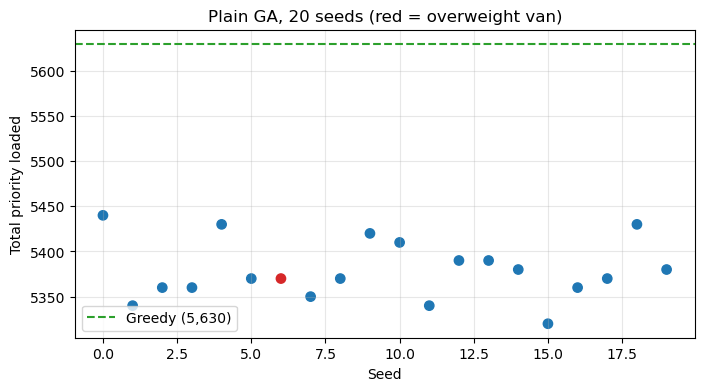

In [8]:
colors = np.where(plain["overweight"], "tab:red", "tab:blue")

plt.figure(figsize=(8, 4))
plt.scatter(plain["seed"], plain["priority"], c=colors, s=45)
plt.axhline(g_prio, color="tab:green", linestyle="--", label=f"Greedy ({g_prio:,.0f})")
plt.xlabel("Seed")
plt.ylabel("Total priority loaded")
plt.title("Plain GA, 20 seeds (red = overweight van)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

| Method | Best | Mean | Worst | Overweight runs |
|---|---|---|---|---|
| Greedy | 5,630.0 | 5,630.0 | 5,630.0 | n/a |
| Plain GA (20 seeds) | 5,440.0 | 5,379.0 | 5,320.0 | 1/20 |

**Check:** an overweight run's priority is inflated, because it carries more parcels than the van allows, so it does not count as a real win. Only compare feasible runs with greedy.

what does the 20-seed result tell you that the single run in 3.2 could not?

**Explaination:** 

> The 20-seed experiment shows that the plain GA did not beat greedy in these recorded runs: its mean priority was 5,379 versus greedy's 5,630, and one run was overweight. Reporting the seed-0 result alone would hide both the run-to-run spread and the infeasible run.

---
### 3.4 Make the GA beat greedy

The handout's two fixes:
1. **Seed one individual with the greedy load.** The starting population contains a good, feasible load, and elitism keeps it.
2. **Repair step.** After crossover and mutation, any overweight child has its lowest priority ÷ volume parcels removed until the load fits. Overloading stops paying.

We test four variants over 20 seeds each: seeding alone, repair alone, both together, and both with a bigger, slower search.

**Prediction:** A seeded GA cannot end up below greedy, because the greedy load is always present in the population and preserved by elitism. There is some room above greedy, but not huge — only parcels with slightly better combinations than greedy can push the total priority higher, so the gains are modest rather than dramatic.

In [9]:
def upper_bound(value, size, cap):
    """Best possible priority if the last parcel could be split (fractional knapsack). No real load can beat this."""
    ratio = value / np.maximum(size, 1)
    used, total = 0.0, 0.0
    for i in np.argsort(-ratio, kind="stable"):
        if used + size[i] <= cap:
            used += size[i]; total += value[i]
        else:
            total += value[i] * (cap - used) / size[i]
            break
    return total

UB = upper_bound(value, size, CAP)
print(f"Greedy:       {g_prio:,.1f}")
print(f"Upper bound:  {UB:,.1f}")
print(f"Headroom:     {UB - g_prio:,.1f} points ({100 * (UB / g_prio - 1):.2f} % above greedy)")

Greedy:       5,630.0
Upper bound:  5,638.1
Headroom:     8.1 points (0.14 % above greedy)


In [10]:
def make_repair(value, size, cap):
    """Returns a function that removes the worst priority-per-cm3 parcels from overweight loads."""
    ratio = value / np.maximum(size, 1)
    worst_first = np.argsort(ratio, kind="stable")

    def repair(pop):
        for c in pop:
            excess = c @ size - cap
            if excess > 0:
                loaded = worst_first[c[worst_first] == 1]          # loaded parcels, worst first
                cum = np.cumsum(size[loaded])
                k = np.searchsorted(cum, excess, side="left") + 1  # how many to drop
                c[loaded[:k]] = 0
        return pop
    return repair

repair = make_repair(value, size, CAP)


def run_ga(value, size, cap, seed=0, pop_size=100, gens=200, pc=0.8, pm=0.01,
           lam=10.0, p_init=0.30, tour=3, elitism=True, seed_with=None, repair=None):
    """Same GA as 3.2, plus an optional repair step. Returns (best chromosome, history)."""
    rng = np.random.default_rng(seed)
    n = len(value)
    pop = (rng.random((pop_size, n)) < p_init).astype(np.int8)
    if seed_with is not None:
        pop[0] = seed_with
    if repair:
        pop = repair(pop)

    history = []
    for _ in range(gens):
        fit = fitness_fn(pop, value, size, cap, lam)
        best = pop[fit.argmax()].copy()
        history.append(fit.max())

        idx = rng.integers(0, pop_size, (2 * pop_size, tour))
        winners = idx[np.arange(2 * pop_size), fit[idx].argmax(axis=1)]
        parents = pop[winners]
        p1, p2 = parents[:pop_size], parents[pop_size:]

        cut = rng.integers(1, n, pop_size)[:, None]
        do_cross = (rng.random(pop_size) < pc)[:, None]
        child = np.where(do_cross & (np.arange(n)[None, :] >= cut), p2, p1)

        flip = rng.random((pop_size, n)) < pm
        child = np.where(flip, 1 - child, child).astype(np.int8)

        if repair:
            child = repair(child)
        if elitism:
            child[0] = best
        pop = child

    fit = fitness_fn(pop, value, size, cap, lam)
    return pop[fit.argmax()], history

In [11]:
variants = {
    "plain GA":              dict(),
    "A: greedy seed":        dict(seed_with=greedy),
    "B: repair":             dict(repair=repair),
    "C: seed + repair":      dict(seed_with=greedy, repair=repair),
    "D: C, bigger search":   dict(seed_with=greedy, repair=repair, pop_size=200, gens=400, pm=0.005),
}

all_runs, rows = {}, []
for name, kw in variants.items():
    df = run_seeds(20, **kw)
    all_runs[name] = df
    rows.append(summarise(df, name))

greedy_row = {"method": "greedy", "best": g_prio, "mean": g_prio, "worst": g_prio,
              "overweight runs": 0, "best feasible": g_prio, "mean vs greedy %": 0.0}
results = pd.DataFrame([greedy_row] + rows)
results.round(1)

,method,best,mean,worst,overweight runs,best feasible,mean vs greedy %
0,greedy,5630.0,5630.0,5630.0,0,5630.0,0.0
1,plain GA,5440.0,5379.0,5320.0,1,5440.0,-4.5
2,A: greedy seed,5630.0,5630.0,5630.0,0,5630.0,0.0
3,B: repair,5610.0,5583.0,5550.0,0,5610.0,-0.8
4,C: seed + repair,5630.0,5630.0,5630.0,0,5630.0,0.0
5,"D: C, bigger search",5630.0,5630.0,5630.0,0,5630.0,0.0


C:\Users\HP\AppData\Local\Temp\ipykernel_31160\1126764081.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([all_runs[k]["priority"] for k in names], labels=[k.split(":")[0] for k in names])


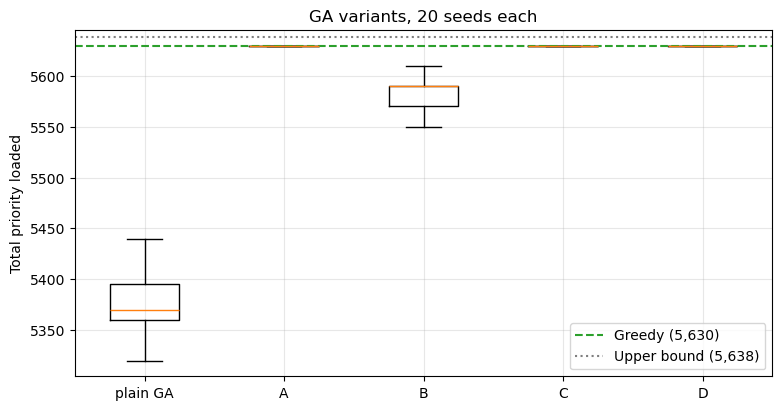

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
names = list(all_runs)
ax.boxplot([all_runs[k]["priority"] for k in names], labels=[k.split(":")[0] for k in names])
ax.axhline(g_prio, color="tab:green", linestyle="--", label=f"Greedy ({g_prio:,.0f})")
ax.axhline(UB, color="tab:gray", linestyle=":", label=f"Upper bound ({UB:,.0f})")
ax.set_ylabel("Total priority loaded")
ax.set_title("GA variants, 20 seeds each")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

| Method | Best | Mean | Worst | Overweight runs |
|---|---|---|---|---|
| Greedy | 5,630.0 | 5,630.0 | 5,630.0 | n/a |
| Plain GA | 5,440.0 | 5,379.0 | 5,320.0 | 1/20 |
| A: greedy seed | 5,630.0 | 5,630.0 | 5,630.0 | 0/20 |
| B: repair | 5,610.0 | 5,583.0 | 5,550.0 | 0/20 |
| C: seed + repair | 5,630.0 | 5,630.0 | 5,630.0 | 0/20 |
| D: bigger search | 5,630.0 | 5,630.0 | 5,630.0 | 0/20 |
| Upper bound | 5,638.1 | n/a | n/a | n/a |

which fix made the biggest difference, and why?

**Explaination:** 

> Greedy seeding made the clearest difference against the plain GA: elitism preserves the feasible greedy chromosome, so the seeded variants matched greedy in all 20 recorded runs. Repair made all tested runs feasible, but repair alone did not beat greedy (mean 5,583 vs. 5,630). The fractional-knapsack upper bound is 5,638.1, so the greedy solution is already within 8.1 priority points (0.14%) of that bound.

The selected route has no package with `hours_left < 3` (the observed minimum among windowed packages is 3.96 h). Therefore the requested under-3-hour inclusion check is not applicable to this route; it is not evidence that the capacity constraint would always allow every urgent package.

---
## Step 4: ACO routing, and racing the real driver

The implementation in `aco_routing.py` includes the station at node 0, routes only through stops with at least one loaded package, and closes every tour back at the station. Driver, nearest-neighbour, and ACO distances use the **same selected stops**; this avoids comparing a reduced route against the original route's 118 deliveries. Distances are Haversine straight-line kilometres, not road distance.

Before using the real route, verify the handout's 8-stop clinic example (page 3): exact optimum 31.45 km, with the specified best route. Then run `python aco_routing.py` for the map and `python planner.py` for the 10-seed `beta = 0, 1, 3, 5` sweep (10 ants, 30 iterations; mean and worst ACO length).

| Route / comparator | Stops | Distance |
|---|---:|---:|
| Driver (loaded stops only) | 102 (including station) | 48.75 km |
| Nearest neighbour | same stops | 46.39 km |
| ACO, beta = 3, seed 0 | same stops | 46.31 km |

| beta | Mean ACO length (10 seeds) | Worst ACO length |
|---:|---:|---:|
| 0 | 100.08 km | 102.06 km |
| 1 | 49.20 km | 50.34 km |
| 3 | 45.78 km | 46.31 km |
| 5 | 45.06 km | 45.41 km |

For this main-route subset, beta = 5 had the lowest mean in the tested sweep. The seed-0 beta = 3 tour was 2.44 km shorter than the same-stop driver benchmark and 0.08 km shorter than nearest neighbour; these are straight-line comparisons on this one route, not a road-time result or a general guarantee.

A shorter straight-line route does not prove that the ACO tour is a better real-world drive: one-way streets, turns, parking, access restrictions, safety, and time windows are not represented in this distance matrix.

In [ ]:
import itertools
import numpy as np
from aco_routing import aco_route, tour_length

clinic_xy = np.array([
    (0, 0), (2, 6), (5, 2), (8, 7), (1, 3), (6, 9), (9, 1), (4, 5)
], dtype=float)
clinic_distances = np.linalg.norm(
    clinic_xy[:, None] - clinic_xy[None, :], axis=2
)
np.fill_diagonal(clinic_distances, 0.0)
clinic_tour, clinic_length, _ = aco_route(
    clinic_distances, n_ants=10, iterations=50, beta=3,
    deposit_scale=100, seed=0
)
exact_length = min(
    tour_length([0, *order], clinic_distances)
    for order in itertools.permutations(range(1, len(clinic_xy)))
)
clinic_names = [
    "Depot", "Clinic1", "Clinic2", "Clinic3", "Clinic4", "Clinic5",
    "Clinic6", "Clinic7"
]
print("ACO tour:", " -> ".join(clinic_names[i] for i in clinic_tour + [0]))
print(f"ACO length: {clinic_length:.2f} km; exhaustive optimum: {exact_length:.2f} km")
assert round(clinic_length, 2) == 31.45
assert abs(clinic_length - exact_length) < 1e-9

---
## Step 5: Integrate and test real-life scenarios

`planner.py` connects route loading, v2 fuzzy priorities, feasible GA loading, nearest-neighbour routing, ACO, and a same-stop driver benchmark. Run it from this folder with `python planner.py`. It prints one dispatcher-ready plan and all scenario summaries. Each scenario uses 10 seeds; the capacity/route summaries show means and min-max ranges, and the ACO beta sweep reports mean and worst length.

### 5.1 Replacement van size

The planner tests capacities at 30%, 40%, and 60% of the selected route's total package volume.

| Capacity | Mean priority | Priority min-max | Mean ACO km | ACO km min-max |
|---:|---:|---:|---:|---:|
| 30% | 5,050.0 | 5,050.0-5,050.0 | 45.46 | 44.86-46.10 |
| 40% | 5,630.0 | 5,630.0-5,630.0 | 46.13 | 45.59-46.77 |
| 60% | 6,430.0 | 6,430.0-6,430.0 | 46.69 | 46.06-47.30 |

### 5.2 Other stations

The two backup routes are from DSE4 and DSE5, distinct from the main route's DLA3 station. The same loading and routing functions are applied without station-specific rules.

| Backup station | GA mean priority (range) | Greedy priority | ACO mean km (range) | Nearest-neighbour mean km (range) |
|---|---:|---:|---:|---:|
| DSE4 | 3,240.0 (3,240.0-3,240.0) | 3,240.0 | 67.01 (65.70-67.91) | 67.70 (67.70-67.70) |
| DSE5 | 3,750.0 (3,750.0-3,750.0) | 3,750.0 | 77.38 (76.72-78.60) | 76.46 (76.46-76.46) |

The GA matches greedy on both backups in these runs. ACO's mean is shorter than nearest neighbour on DSE4, but longer on DSE5; it does not beat the baseline on every route.

### 5.3 Rush orders

For each paired seed, five previously no-window packages are assigned a one-hour closing window after departure and rescored with the same v2 fuzzy system. The planner reports mean total priority and the package IDs displaced from the baseline selection. This is a simulation: the original dataset does not label these five packages as rush orders.

| Plan | Mean total priority (range, 10 seeds) |
|---|---:|
| Baseline | 5,630.0 (5,630.0-5,630.0) |
| Five rush orders | 5,930.0 (5,930.0-5,930.0) |

The same package was bumped in all 10 paired runs: `PackageID_3377aa23-5eee-42e6-bd4c-82ced72ed4c5`.

### Run the integrated planner and scenario tests

In [ ]:
from planner import run_planner

run_planner()

---
## Step 6: Report and run instructions

### Prepare the report

1. Write a 4-6 page report using the completed route profile, code checks, and scenario outputs in this planner.
2. Cite the Amazon Last Mile Routing Research Challenge dataset: Merchán et al. (2022), *2021 Amazon Last Mile Routing Research Challenge: Data Set*, Transportation Science, doi:10.1287/trsc.2022.1173.
3. Describe the three supplied files: `route_data.json`, `package_data.json`, and `actual_sequences.json`.
4. Explain how the fuzzy priority system, genetic algorithm, and ant colony optimization relate to the lecture examples.
5. Report the measured main-route and scenario results shown in Steps 1-5. Do not claim that the GA beats greedy on this main route; the improved GA matches it in the recorded runs.
6. State which inputs come from the dataset and which are assumptions: the priority rules, replacement-van capacity fractions, simulated rush orders, and straight-line distances.
7. State that the route distances are Haversine estimates, not road distances or travel times, and that on-time delivery was not evaluated.

### Run the project

1. Open a terminal in the project folder containing `planner.py`.
2. Check that the data files exist in `almrrc2021/almrrc2021-data-training/model_build_inputs/`: `route_data.json`, `package_data.json`, and `actual_sequences.json`.
3. If any data file is missing, download the dataset files by running:

   ```powershell
   python download_data.py
   ```

4. If the required Python packages are not installed, install NumPy, Pandas, and Matplotlib:

   ```powershell
   python -m pip install numpy pandas matplotlib
   ```

5. Run the integrated dispatcher plan and all three scenarios:

   ```powershell
   python planner.py
   ```

6. Read the terminal output for the selected routes, loaded and unassigned package counts, stop order, distance comparisons, and scenario tables.
7. To run a component separately, use `python fuzzy_priority.py`, `python ga_loading.py`, `python aco_routing.py`, or `python route_profile.py`.
8. To run the integrated planner inside this notebook, execute the Step 5 cell that calls `run_planner()`.
9. Compare driver, nearest-neighbour, and ACO distances only when they use the same selected stops.